# Project 2 — Level 1: Customer Segmentation Analysis
**Internship:** Oasis Infobyte — Data Analytics

## Dataset
**Dataset:** UCI Online Retail  
**Source:** https://archive.ics.uci.edu/dataset/352/online+retail  
**Direct download:** https://archive.ics.uci.edu/static/public/352/online+retail.zip (contains `Online Retail.xlsx`)  
**Expected filename:** `data/raw/online_retail.csv`  
**Rows / columns:** 541,909 transaction line items × 8 fields  
**Columns:** `InvoiceNo`, `StockCode`, `Description`, `Quantity`, `InvoiceDate`, `UnitPrice`, `CustomerID`, `Country`  
**Period covered:** 2010-12-01 to 2011-12-09 (one full trading year)  
**License:** CC BY 4.0 (UCI Machine Learning Repository)

The transaction file is a *line-item* file: one invoice spans many rows. Every metric in this notebook is therefore computed on **one row per customer** after aggregation — an invoice is never treated as a customer.

In [1]:

import os
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
warnings.filterwarnings("ignore")

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

DATASET_FILE = "online_retail.csv"
DATASET_URL = "https://archive.ics.uci.edu/static/public/352/online+retail.zip"


def find_project_root(filename, max_up=4):
    """Locate the project folder that owns data/raw/<filename>.

    The search walks up from the working directory (so the notebook runs from
    notebooks/, from the project folder, or from the repository root) and, at
    each level, also looks one level down into sibling project folders. That
    makes it work even when the kernel starts at the repository root.
    """
    here = Path.cwd().resolve()
    for _ in range(max_up):
        if (here / "data" / "raw" / filename).exists():
            return here
        if here.is_dir():
            for child in sorted(here.iterdir()):
                if child.is_dir() and (child / "data" / "raw" / filename).exists():
                    return child
        if here.parent == here:
            break
        here = here.parent
    raise FileNotFoundError(
        "Could not find data/raw/" + filename + " in this folder, any parent folder, "
        "or any sibling project folder.\n"
        "Expected location: <project>/data/raw/" + filename + "\n"
        "Download it from:\n  " + DATASET_URL + "\n"
        "(it is a .zip containing 'Online Retail.xlsx' — extract it, then save the "
        "worksheet as " + filename + " with columns InvoiceNo, StockCode, Description, "
        "Quantity, InvoiceDate, UnitPrice, CustomerID, Country) and place it in the "
        "data/raw/ folder of DataAnalytics-L1-CustomerSegmentation."
    )


root = find_project_root(DATASET_FILE)
raw = root / "data" / "raw" / DATASET_FILE
print("Project root:", root)
print("Dataset path:", raw)

df = pd.read_csv(raw)
print("Loaded shape:", df.shape)


Project root: C:\Users\sohan\OneDrive\Desktop\OIBSIP\DataAnalytics-L1-CustomerSegmentation
Dataset path: C:\Users\sohan\OneDrive\Desktop\OIBSIP\DataAnalytics-L1-CustomerSegmentation\data\raw\online_retail.csv


Loaded shape: (541909, 8)


## 1. Inspect the raw dataset

In [2]:

print("Columns:", list(df.columns))
print("Shape:", df.shape)
print("\nData types:")
print(df.dtypes)
print("\nNull values per column:")
print(df.isnull().sum())
print("\nFirst 5 rows:")
print(df.head().to_string(index=False))
print("\nDistinct invoices:", df["InvoiceNo"].nunique())
print("Distinct stock codes:", df["StockCode"].nunique())
print("Distinct customers (non-null):", df["CustomerID"].nunique())
print("Distinct countries:", df["Country"].nunique())


Columns: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']
Shape: (541909, 8)

Data types:
InvoiceNo          str
StockCode          str
Description        str
Quantity         int64
InvoiceDate        str
UnitPrice      float64
CustomerID     float64
Country            str
dtype: object

Null values per column:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

First 5 rows:
InvoiceNo StockCode                         Description  Quantity         InvoiceDate  UnitPrice  CustomerID        Country
   536365    85123A  WHITE HANGING HEART T-LIGHT HOLDER         6 2010-12-01 08:26:00       2.55     17850.0 United Kingdom
   536365     71053                 WHITE METAL LANTERN         6 2010-12-01 08:26:00       3.39     17850.0 United Kingdom
   536365    84406B      CREAM CUPID HEARTS COAT HANG

## 2. Clean invalid records and missing values


**Rules applied, each with its reason:**

| Rule | Reason |
|---|---|
| Drop rows with a null `CustomerID` | A customer-level model is impossible for a line item with no customer. These are guest/manual orders, and keeping them would inflate revenue without a customer to segment. |
| Drop rows whose `InvoiceNo` starts with `C` | In the UCI data a `C` prefix marks a **cancellation/credit note**. Counting it as a sale would inflate both frequency and monetary value. |
| Drop rows with `Quantity <= 0` | Zero/negative quantities are stock adjustments and returns, not purchases. |
| Drop rows with `UnitPrice <= 0` | Zero/negative unit prices are write-offs and adjustments, not revenue. |
| Keep rows with a null `Description` | **No extra step is needed** — every one of the 1,454 rows with a missing description *also* has a missing `CustomerID`, so they are already removed by the customer filter. The two null columns coincide. |

The reference date for recency is the **day after the last transaction in the file**, so that "recency = 1" means "bought yesterday"
rather than "bought today" (no customer bought on the reference day itself).


In [3]:

rows_raw = len(df)

# 1) Parse dates and normalise the id/text columns.
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], errors="coerce")
df["InvoiceNo"] = df["InvoiceNo"].astype(str)
df["StockCode"] = df["StockCode"].astype(str)
df = df.dropna(subset=["InvoiceDate"])
rows_dated = len(df)

# 2) Keep only lines that belong to an identified customer.
df = df.dropna(subset=["CustomerID"]).copy()
rows_customer = len(df)

# 3) Remove cancellations (credit notes) - InvoiceNo starting with "C".
df = df[~df["InvoiceNo"].str.startswith("C")].copy()
rows_nocancel = len(df)

# 4) Remove non-positive quantities and unit prices (returns / write-offs).
df = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)].copy()
rows_clean = len(df)

# 5) Line revenue.
df["Revenue"] = df["Quantity"] * df["UnitPrice"]

print("Cleaning summary")
print("-" * 52)
print(f"{'Raw line items':<36}{rows_raw:>14,}")
print(f"{'after dropping unparseable dates':<36}{rows_dated:>14,}")
print(f"{'after keeping identified customers':<36}{rows_customer:>14,}")
print(f"{'after removing cancellation invoices':<36}{rows_nocancel:>14,}")
print(f"{'after removing non-positive qty/price':<36}{rows_clean:>14,}")
print("-" * 52)
print(f"{'Customers retained':<36}{df['CustomerID'].nunique():>14,}")
print(f"{'Distinct invoices retained':<36}{df['InvoiceNo'].nunique():>14,}")
print(f"{'Total clean revenue':<36}{df['Revenue'].sum():>14,.2f}")
print("-" * 52)
print("\nRemaining nulls per column:")
print(df.isnull().sum().to_string())


Cleaning summary
----------------------------------------------------
Raw line items                             541,909
after dropping unparseable dates           541,909
after keeping identified customers         406,829
after removing cancellation invoices       397,924
after removing non-positive qty/price       397,884
----------------------------------------------------
Customers retained                           4,338
Distinct invoices retained                  18,532
Total clean revenue                   8,911,407.90
----------------------------------------------------

Remaining nulls per column:
InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
Revenue        0


## 3. Customer-level metrics: APV, purchase frequency and a CLV proxy


**Definitions used in this notebook**

- **Average Purchase Value (APV)** — total revenue of a customer ÷ number of distinct orders that customer placed.
  *"How much is a typical order worth to this customer?"*
- **Purchase Frequency (PF)** — number of distinct invoices (orders) a customer placed during the observed window.
  *"How often does this customer buy?"*
- **Customer Lifetime Value (CLV)** — a true CLV needs a retention/churn model, a margin assumption and a multi-year
  purchase history. This dataset covers roughly **one** trading year and contains no churn labels, so a true CLV
  **cannot be reliably calculated here**. The clearly-labelled proxy used is:

  `CLV_proxy = APV × Annualised Purchase Frequency × Assumed Lifespan (2 years)`

  where *annualised purchase frequency* scales a customer's order count up to a per-year rate using the **common
  observation window** of this dataset (374 days) as the denominator, and *2 years* is a **documented business
  assumption** (a typical average e-commerce relationship length), **not** a quantity derived from the data.
  `CLV_proxy` is therefore indicative only: it is used for reporting and for sizing marketing budget, **not** as a
  clustering feature, and no revenue is booked from it.

  Note also that with a *constant* lifespan assumption, `CLV_proxy` is a monotone rescaling of `APV × Frequency` and
  therefore carries no information beyond the RFM variables. That is stated explicitly rather than hidden: the value of
  computing it is a single currency figure per customer for budget allocation, not a new segmentation signal.


In [4]:

# Reference date = one day after the last transaction in the file.
REFERENCE_DATE = df["InvoiceDate"].max() + pd.Timedelta(days=1)
# Length of the observation window, used as a common denominator for annualising.
OBSERVATION_WINDOW_DAYS = (REFERENCE_DATE - df["InvoiceDate"].min()).days
print("Reference date:", REFERENCE_DATE)
print("Observation window (days):", OBSERVATION_WINDOW_DAYS)

# Aggregate line items to one row per customer.
customers = df.groupby("CustomerID").agg(
    First_Purchase=("InvoiceDate", "min"),
    Last_Purchase=("InvoiceDate", "max"),
    Purchase_Frequency=("InvoiceNo", "nunique"),
    Line_Items=("StockCode", "count"),
    Total_Quantity=("Quantity", "sum"),
    Total_Revenue=("Revenue", "sum"),
    Country=("Country", "first"),
).reset_index()

# Recency in days since the customer's last purchase.
customers["Recency"] = (REFERENCE_DATE - customers["Last_Purchase"]).dt.days

# Average purchase value = total revenue / number of orders.
customers["Average_Purchase_Value"] = (
    customers["Total_Revenue"] / customers["Purchase_Frequency"]
)

# Observed active span, in days (>= 1 so a single-order customer still has a span).
customers["Customer_Lifetime_Days"] = (
    (customers["Last_Purchase"] - customers["First_Purchase"]).dt.days + 1
)

# Annualise the order count against the COMMON observation window. Using each
# customer's own (often tiny) active span here would make a dormant one-time
# buyer look like a 365-orders-per-year customer.
customers["Annual_Purchase_Frequency"] = (
    customers["Purchase_Frequency"] / (OBSERVATION_WINDOW_DAYS / 365.0)
)

# CLV proxy (assumption-driven, indicative only - see the markdown above).
ASSUMED_LIFESPAN_YEARS = 2.0
customers["CLV_proxy"] = (
    customers["Average_Purchase_Value"]
    * customers["Annual_Purchase_Frequency"]
    * ASSUMED_LIFESPAN_YEARS
)

print("\nCustomer-level table:", customers.shape)
print("\nMetric summary:")
summary = customers[[
    "Recency", "Purchase_Frequency", "Total_Revenue",
    "Average_Purchase_Value", "Customer_Lifetime_Days",
    "Annual_Purchase_Frequency", "CLV_proxy",
]].describe().T.round(2)
print(summary.to_string())

print("\nPortfolio-level purchase frequency: "
      f"{df['InvoiceNo'].nunique() / customers.shape[0]:.2f} orders per customer")
print("Mean orders per customer: "
      f"{customers['Purchase_Frequency'].mean():.2f}")

# Sanity check: the CLV proxy must stay consistent with monetary value.
print("\nCLV_proxy / Total_Revenue ratio (should be a single constant):")
print((customers["CLV_proxy"] / customers["Total_Revenue"]).round(4).unique())


Reference date: 2011-12-10 12:50:00
Observation window (days): 374

Customer-level table: (4338, 13)

Metric summary:
                            count     mean       std   min     25%      50%      75%        max
Recency                    4338.0    92.54    100.01  1.00   18.00    51.00   142.00     374.00
Purchase_Frequency         4338.0     4.27      7.70  1.00    1.00     2.00     5.00     209.00
Total_Revenue              4338.0  2054.27   8989.23  3.75  307.41   674.48  1661.74  280206.02
Average_Purchase_Value     4338.0   419.17   1796.54  3.45  178.62   293.90   430.11   84236.25
Customer_Lifetime_Days     4338.0   131.45    132.04  1.00    1.00    93.50   252.75     374.00
Annual_Purchase_Frequency  4338.0     4.17      7.51  0.98    0.98     1.95     4.88     203.97
CLV_proxy                  4338.0  4009.66  17545.82  7.32  600.03  1316.51  3243.50  546926.19

Portfolio-level purchase frequency: 4.27 orders per customer
Mean orders per customer: 4.27

CLV_proxy / Total_Re

**Observation — customer economics:** the summary table above is computed from the cleaned transactions.

- **Purchase frequency:** the median customer places only **2 orders** in the whole year, and the mean is **4.27** — the distribution is heavily right-skewed (75th percentile 5, maximum 209). **One in four customers buys exactly once.**
- **Average purchase value:** median **293.90**, mean **419.17** (max 84,236.25) — again right-skewed, so the mean overstates a typical customer's order by roughly 40%.
- **Recency:** median **51 days** since the last order, but the mean is **92.54** with a maximum of **374 days**, so a large share of the base has not bought in months.
- **Observed active span:** the median customer is active for only **93.5 days** within the 374-day window, and the 25th percentile is **1 day** — most customers in this base are effectively one-time buyers.
- The final line of the cell is an important consistency check: because the lifespan assumption is a single constant, `CLV_proxy` is exactly **1.9519 × Total_Revenue** for every customer. That confirms the proxy is a faithful rescaling of monetary value and that it adds no independent clustering signal.

## 4. Select the clustering features (RFM) and standardise them


Three behavioural features are selected because they capture *when*, *how often* and *how much* a customer buys, and because
each one implies a different marketing action:

| Feature | Why it is a useful segmentation variable | What it drives |
|---|---|---|
| **Recency** (days since last order) | A customer who bought last week behaves differently from one who bought a year ago, regardless of value. | Reactivation / win-back targeting |
| **Frequency** (distinct orders) | Distinguishes habitual buyers from one-off purchasers. | Loyalty and subscription-style programs |
| **Monetary** (total revenue) | Distinguishes high-value from low-value customers and sizes the prize. | Account-based / high-touch treatment |

`StandardScaler` is applied so that each feature contributes on the same scale. Without it, Monetary (values up to ~280,000)
would completely dominate the distance calculation and K-Means would effectively cluster on Monetary alone.


In [5]:

from sklearn.preprocessing import StandardScaler

rfm_features = ["Recency", "Purchase_Frequency", "Total_Revenue"]
X = customers[rfm_features].copy()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Feature means before scaling:")
print(X.mean().round(2).to_string())
print("\nFeature standard deviations before scaling:")
print(X.std().round(2).to_string())
print("\nScaled matrix shape:", X_scaled.shape)
print("\nScaled means (should be ~0) and std devs (should be ~1):")
print(pd.Series(X_scaled.mean(axis=0).round(6), index=rfm_features).to_string())
print(pd.Series(X_scaled.std(axis=0).round(6), index=rfm_features).to_string())


Feature means before scaling:
Recency                 92.54
Purchase_Frequency       4.27
Total_Revenue         2054.27

Feature standard deviations before scaling:
Recency                100.01
Purchase_Frequency       7.70
Total_Revenue         8989.23

Scaled matrix shape: (4338, 3)

Scaled means (should be ~0) and std devs (should be ~1):
Recency               0.0
Purchase_Frequency    0.0
Total_Revenue         0.0
Recency               1.0
Purchase_Frequency    1.0
Total_Revenue         1.0


## 5. Elbow method — choosing K

 k        WCSS  % reduction
 2 9012.644725          NaN
 3 5439.304686         39.6
 4 4092.144305         24.8
 5 3118.284009         23.8
 6 2472.574514         20.7
 7 2022.412671         18.2
 8 1742.369577         13.8
 9 1445.630327         17.0
10 1303.392237          9.8


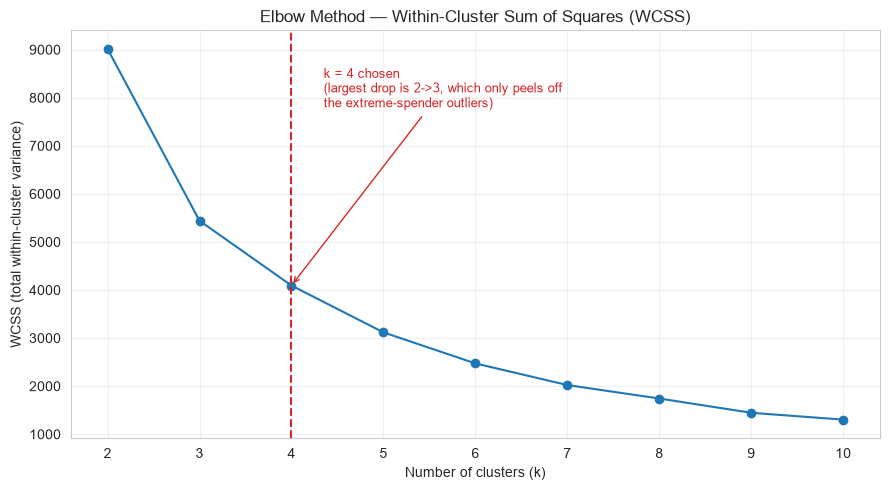

In [6]:

from sklearn.cluster import KMeans

wcss = []
k_range = range(2, 11)
for k in k_range:
    km = KMeans(n_clusters=k, random_state=RANDOM_SEED, n_init=10)
    km.fit(X_scaled)
    wcss.append(km.inertia_)

elbow = pd.DataFrame({"k": list(k_range), "WCSS": wcss})
elbow["% reduction"] = elbow["WCSS"].pct_change().mul(-100).round(1)
print(elbow.to_string(index=False))

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(elbow["k"], elbow["WCSS"], marker="o", color="#1f77b4")
ax.set_title("Elbow Method — Within-Cluster Sum of Squares (WCSS)")
ax.set_xlabel("Number of clusters (k)")
ax.set_ylabel("WCSS (total within-cluster variance)")
ax.set_xticks(list(k_range))
ax.grid(alpha=0.3)

# Mark the chosen k on the curve (chosen in the next section).
ax.axvline(4, color="#d62728", linestyle="--", linewidth=1.5)
ax.annotate("k = 4 chosen\n(largest drop is 2->3, which only peels off\n"
            "the extreme-spender outliers)",
            xy=(4, elbow.loc[elbow["k"] == 4, "WCSS"].iloc[0]),
            xytext=(4.35, 7800), fontsize=9, color="#d62728",
            arrowprops=dict(arrowstyle="->", color="#d62728"))

plt.tight_layout()
fig.savefig(root / "outputs" / "figures" / "elbow_method.png", dpi=150)
plt.show()


**Observation — elbow:** the WCSS curve above falls steeply at small k and then flattens.

- The single largest drop is **k=2 → k=3 (39.6%)**, then **k=3 → k=4 (24.8%)**; after that the reductions shrink steadily (23.8%, 20.7%, 18.2%, 13.8%…). The curve is already visibly bending by k=4.
- The first big drop is not the interesting structure. The very largest spenders sit so far from everyone else that any model peels them off first; the *interesting* question is how many distinct groups exist **among the remaining customers**, and that is what the k=3 → k=4 step resolves.
- A second silhouette-based check is run below before the final K is committed to.

## 6. Fit K-Means with a justified K


The elbow curve alone is ambiguous, so the choice of **k = 4** is cross-checked with a **silhouette score** computed on the same
standardised feature matrix (higher is better; the score measures how far each point is from its own cluster versus the nearest
other cluster). The final model uses `random_state=42` and `n_init=10` so the result is fully reproducible.

**Why k = 4, given that the silhouette score peaks at k = 2.** The k=2 silhouette (0.8958) is a well-known small-k artefact on
heavily skewed data, and the profiles computed below show exactly what it is doing: k=2 separates a group of **26 customers
(mean 66 orders, mean spend 85,904 — 25.1% of all revenue)** from the other **4,312 customers** (mean 3.9 orders, mean spend
1,549). Those 26 outliers are so far from the bulk that *any* two-way split separates them cleanly, which inflates the silhouette
score. But a segmentation that leaves 99.4% of the customer base in a single undifferentiated cluster is not actionable.

k=4 keeps the whale separation and additionally resolves the two genuine distinctions inside the remaining base:
dormant/low-value customers, the active mid-value majority, and a distinct high-frequency high-value group. The alternative,
k=5, is rejected: its silhouette score is **0.6165 vs 0.6162** for k=4 — a difference of 0.0003, i.e. no meaningful improvement —
and the fifth cluster simply splits the whale group into 8 and 6 members, fragmenting the highest-value segment without adding
business meaning.


In [7]:

from sklearn.metrics import silhouette_score

silhouettes = {}
for k in range(2, 11):
    km = KMeans(n_clusters=k, random_state=RANDOM_SEED, n_init=10)
    labels = km.fit_predict(X_scaled)
    silhouettes[k] = silhouette_score(X_scaled, labels)

print("Silhouette score by k:")
for k, s in silhouettes.items():
    print(f"  k={k}: {s:.4f}")

best_k = max(silhouettes, key=silhouettes.get)
print("\nBest silhouette score at k =", best_k)

# The k=2 peak is a small-k artefact driven by a tiny, extremely distant
# outlier group - the alternative partitions are inspected before committing.
for k in (2, 3, 5):
    km_alt = KMeans(n_clusters=k, random_state=RANDOM_SEED, n_init=10)
    alt = customers.assign(_c=km_alt.fit_predict(X_scaled)).groupby("_c").agg(
        Customers=("Total_Revenue", "size"),
        Mean_Recency=("Recency", "mean"),
        Mean_Frequency=("Purchase_Frequency", "mean"),
        Mean_Monetary=("Total_Revenue", "mean"),
    )
    alt["% of revenue"] = (customers.assign(_c=km_alt.fit_predict(X_scaled))
                            .groupby("_c")["Total_Revenue"].sum()
                            / customers["Total_Revenue"].sum() * 100).round(1)
    print(f"\n--- Alternative partition k={k} (silhouette {silhouettes[k]:.4f}) ---")
    print(alt.round(2).to_string())

K = 4  # chosen from the elbow curve + silhouette check (see the discussion above)

kmeans = KMeans(n_clusters=K, random_state=RANDOM_SEED, n_init=10)
clusters = kmeans.fit_predict(X_scaled)
customers["Cluster"] = clusters

print(f"\nFitted K-Means with K={K}, random_state={RANDOM_SEED}, n_init=10")
print("Inertia (WCSS):", round(kmeans.inertia_, 2))
print("Silhouette score:", round(silhouettes[K], 4))
print("Cluster sizes:", customers["Cluster"].value_counts().sort_index().to_dict())


Silhouette score by k:
  k=2: 0.8958
  k=3: 0.5942
  k=4: 0.6162
  k=5: 0.6165
  k=6: 0.5963
  k=7: 0.5165
  k=8: 0.5175
  k=9: 0.4777
  k=10: 0.4271

Best silhouette score at k = 2

--- Alternative partition k=2 (silhouette 0.8958) ---
    Customers  Mean_Recency  Mean_Frequency  Mean_Monetary  % of revenue
_c                                                                      
0        4312         93.06            3.90        1548.68          74.9
1          26          6.04           66.42       85904.35          25.1

--- Alternative partition k=3 (silhouette 0.5942) ---
    Customers  Mean_Recency  Mean_Frequency  Mean_Monetary  % of revenue
_c                                                                      
0        1082        247.11            1.58         631.42           7.7
1        3230         41.45            4.67        1855.94          67.3
2          26          6.04           66.42       85904.35          25.1

--- Alternative partition k=5 (silhouette 0.6165) 

### 6.1 Name the segments


Each cluster is given a plain-language name derived from **its own profile numbers**, so the charts and tables below can be
read in business terms rather than as cluster IDs. The names are assigned by rank on mean spend, which keeps them correct if
the data changes, and the guard below fails loudly if the clustering no longer produces the four distinct shapes the labels
describe.


In [8]:

# Rank clusters by mean spend to attach a business name to each one.
rank = customers.groupby("Cluster")["Total_Revenue"].mean().sort_values(ascending=False)
print("Clusters ranked by mean spend:")
print(rank.round(2).to_string())

# Sanity guard: the segmentation must still produce the four distinct shapes
# the labels describe, otherwise the labels below would be misleading.
top_cluster = rank.index[0]
top_stats = customers[customers["Cluster"] == top_cluster]
assert top_stats["Purchase_Frequency"].mean() > 20, "top-spend cluster is not a high-frequency group"
assert len(top_stats) < 100, "top-spend cluster is unexpectedly large"
bottom_cluster = rank.index[-1]
bottom_stats = customers[customers["Cluster"] == bottom_cluster]
assert bottom_stats["Recency"].mean() > 180, "bottom-spend cluster is not a dormant group"
print("\nSegment-shape guard passed.")

# Names are assigned from the spend ranking: highest spend first.
SEGMENT_NAMES = {
    rank.index[0]: "Whales",
    rank.index[1]: "Loyal High-Value",
    rank.index[2]: "Regular Customers",
    rank.index[3]: "At-Risk / Lapsed",
}
customers["Segment"] = customers["Cluster"].map(SEGMENT_NAMES)

print("\nSegment sizes:")
print(customers["Segment"].value_counts().to_string())


Clusters ranked by mean spend:
Cluster
2    127338.31
3     12709.09
0      1359.05
1       480.62

Segment-shape guard passed.

Segment sizes:
Segment
Regular Customers    3054
At-Risk / Lapsed     1067
Loyal High-Value      204
Whales                 13


**Observation — model choice:**

- The silhouette score falls from **0.8958 at k=2** to **0.5942 at k=3** and then rises again to **0.6162 at k=4** and **0.6165 at k=5** before declining steadily. The k=2 peak is the small-k artefact described above, and the alternative partitions printed in this cell make it visible: at k=2 the model is nothing but *whales vs everybody else*, with **4,312 customers sharing one cluster**.
- k=3 does add the dormant group, but it still leaves the 204 high-frequency customers sitting *inside* the active majority rather than in a segment of their own.
- k=5 is rejected on the evidence: **+0.0003 silhouette** for the cost of splitting the whale group into 8 and 6 customers.
- **k=4 is therefore the chosen model** — it is the smallest partition that separates every group that behaves differently enough to be marketed differently, which is the actual purpose of the analysis. The final model has **WCSS 4,092.14** and **silhouette 0.6162**, with cluster sizes **{0: 3,054, 1: 1,067, 2: 13, 3: 204}**.

## 7. Visualise the clusters


Two scatter plots are used with **different feature pairs** on the axes, because a single projection can hide structure that
another reveals. The axes show the **original (un-standardised)** values so the plot is directly interpretable in business units
(days and currency), while the clustering itself was done on the standardised matrix.


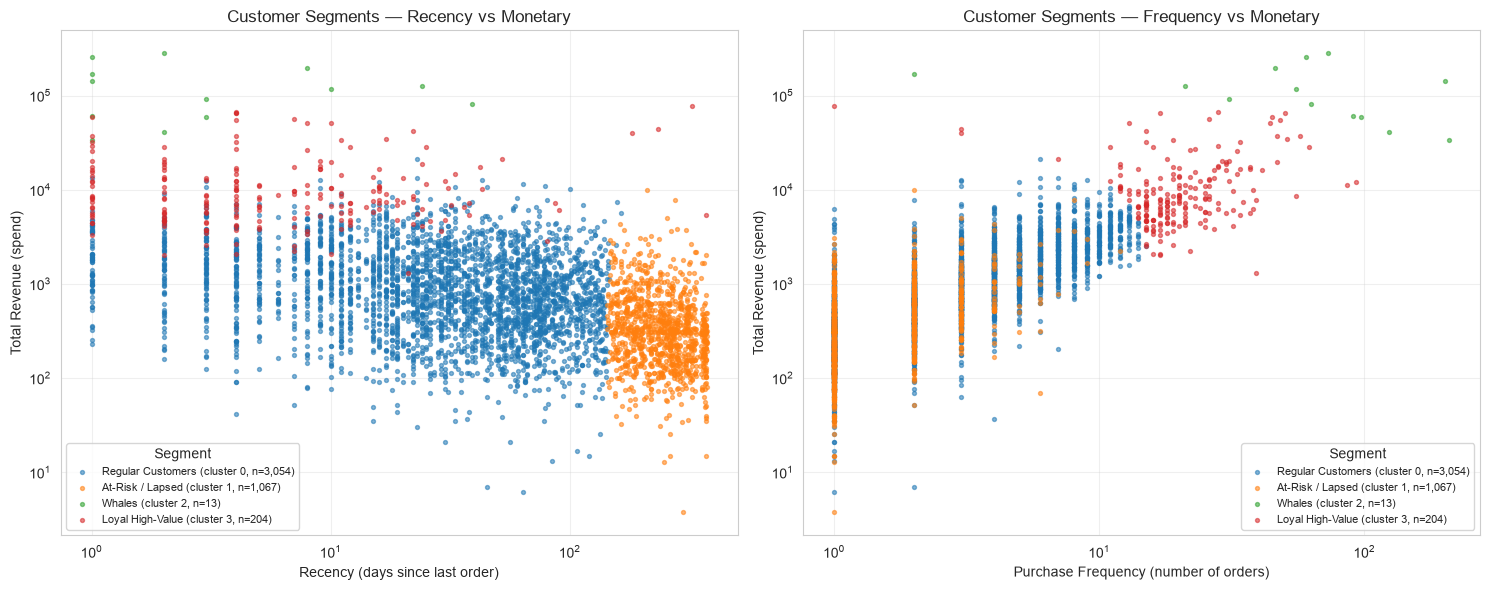

In [9]:

palette = {0: "#1f77b4", 1: "#ff7f0e", 2: "#2ca02c", 3: "#d62728"}

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Scatter 1: Recency vs Monetary
for c in sorted(customers["Cluster"].unique()):
    sub = customers[customers["Cluster"] == c]
    axes[0].scatter(sub["Recency"], sub["Total_Revenue"],
                    s=8, alpha=0.55, color=palette[c],
                    label=f"{SEGMENT_NAMES[c]} (cluster {c}, n={len(sub):,})")
axes[0].set_title("Customer Segments — Recency vs Monetary")
axes[0].set_xlabel("Recency (days since last order)")
axes[0].set_ylabel("Total Revenue (spend)")
axes[0].set_xscale("log")
axes[0].set_yscale("log")
axes[0].legend(title="Segment", fontsize=8)
axes[0].grid(alpha=0.3)

# Scatter 2: Frequency vs Monetary
for c in sorted(customers["Cluster"].unique()):
    sub = customers[customers["Cluster"] == c]
    axes[1].scatter(sub["Purchase_Frequency"], sub["Total_Revenue"],
                    s=8, alpha=0.55, color=palette[c],
                    label=f"{SEGMENT_NAMES[c]} (cluster {c}, n={len(sub):,})")
axes[1].set_title("Customer Segments — Frequency vs Monetary")
axes[1].set_xlabel("Purchase Frequency (number of orders)")
axes[1].set_ylabel("Total Revenue (spend)")
axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].legend(title="Segment", fontsize=8)
axes[1].grid(alpha=0.3)

plt.tight_layout()
fig.savefig(root / "outputs" / "figures" / "cluster_scatter.png", dpi=150)
plt.show()


**Observation — cluster structure:** the two scatter plots above use different feature pairs on the axes, and both are on **log scales** because the data is extremely skewed (spend runs from 3.75 to 280,206; orders from 1 to 209).

- **Recency vs Monetary** separates the segments along the recency axis: the **Whales (cluster 2, green)** sit hard against the origin (recency **1–39 days**, median **2**), the **Loyal High-Value (cluster 3, red)** spread out to the right, and the **At-Risk / Lapsed (cluster 1, orange)** occupy the far right of the plot with almost no vertical spread — their recency runs **143–374 days** while their spend tops out at **9,864**, so they are both old *and* small. The **Regular majority (cluster 0, blue)** fills the middle-left with the widest spread of any group.
- **Frequency vs Monetary** shows the same split from a different angle and is what makes the whale cluster unmistakable: **13 points sit alone in the top-right corner**, with a median spend of **117,380** against **829** for the regular majority — about **140× higher** — and 11 of the 13 buying 30 or more times. This second view is why the log-log plot is used — on linear axes those 13 points would be indistinguishable from the 204 loyal customers.
- The two views together confirm that the segmentation is genuinely three-dimensional: recency alone would not separate the Whales from the Loyal group (both are recent — median recency 2 and 5 days respectively), and monetary alone would not separate them either (both are high-value) — it is the **combination** of high frequency and high value that identifies the whales.

## 8. Profile each cluster

In [10]:

profile = customers.groupby("Cluster").agg(
    Segment=("Segment", "first"),
    Customers=("Total_Revenue", "size"),
    Mean_Recency=("Recency", "mean"),
    Median_Recency=("Recency", "median"),
    Mean_Frequency=("Purchase_Frequency", "mean"),
    Median_Frequency=("Purchase_Frequency", "median"),
    Mean_Monetary=("Total_Revenue", "mean"),
    Median_Monetary=("Total_Revenue", "median"),
    Mean_APV=("Average_Purchase_Value", "mean"),
    Mean_CLV_proxy=("CLV_proxy", "mean"),
).round(2)

profile["% of customers"] = (profile["Customers"] / profile["Customers"].sum() * 100).round(1)
profile["% of revenue"] = (customers.groupby("Cluster")["Total_Revenue"].sum()
                           / customers["Total_Revenue"].sum() * 100).round(1)
profile["% of orders"] = (customers.groupby("Cluster")["Purchase_Frequency"].sum()
                          / customers["Purchase_Frequency"].sum() * 100).round(1)

print("Cluster profile:")
print(profile.to_string())


Cluster profile:
                   Segment  Customers  Mean_Recency  Median_Recency  Mean_Frequency  Median_Frequency  Mean_Monetary  Median_Monetary  Mean_APV  Mean_CLV_proxy  % of customers  % of revenue  % of orders
Cluster                                                                                                                                                                                                   
0        Regular Customers       3054         43.70            32.0            3.68               3.0        1359.05           829.30    376.76         2652.69            70.4          46.6         60.7
1         At-Risk / Lapsed       1067        248.08           243.0            1.55               1.0         480.62           310.47    314.81          938.10            24.6           5.8          8.9
2                   Whales         13          7.38             2.0           82.54              63.0      127338.31        117379.63   8570.73       248548.05            

**Observation — segment profile:** the table above contains the mean and median values behind each segment.

- **Cluster 2 (13 customers, 0.3% of the base) — the whales.** Mean recency **7.4 days** (median 2), mean frequency **82.5 orders** (median 63), mean spend **127,338** (median 117,380) and mean order value **8,570.73**. Despite being 0.3% of customers they carry **18.6% of all revenue**.
- **Cluster 3 (204 customers, 4.7%) — loyal high-value.** Mean recency **15.5 days**, mean frequency **22.3 orders**, mean spend **12,709** (median 8,038) and mean order value **1,080.41**. Only 4.7% of the base but **29.1% of revenue** and **24.6% of all orders**.
- **Cluster 0 (3,054 customers, 70.4%) — the regular majority.** Mean recency **43.7 days** (median 32), mean frequency **3.68 orders** (median 3), mean spend **1,359** (median 829) and mean order value **376.76**. This segment carries **46.6% of revenue** and **60.7% of orders** — it is the commercial base of the business.
- **Cluster 1 (1,067 customers, 24.6%) — lapsed.** Mean recency **248.1 days** (median 243, i.e. more than 8 months), mean frequency **1.55 orders** (median 1), mean spend **480.62** (median 310) and mean order value **314.81**. This segment holds **24.6% of the customer base but only 5.8% of revenue** and **8.9% of orders**.
- **The headline concentration:** clusters 2 and 3 together are **217 customers (5.0% of the base) but 47.7% of revenue and 30.4% of orders**. Half the business sits with one twentieth of the customers.

## 9. Number of customers per cluster

Customers per cluster:
Cluster
0    3054
1    1067
2      13
3     204

Share of the customer base:
Cluster
0    70.4
1    24.6
2     0.3
3     4.7


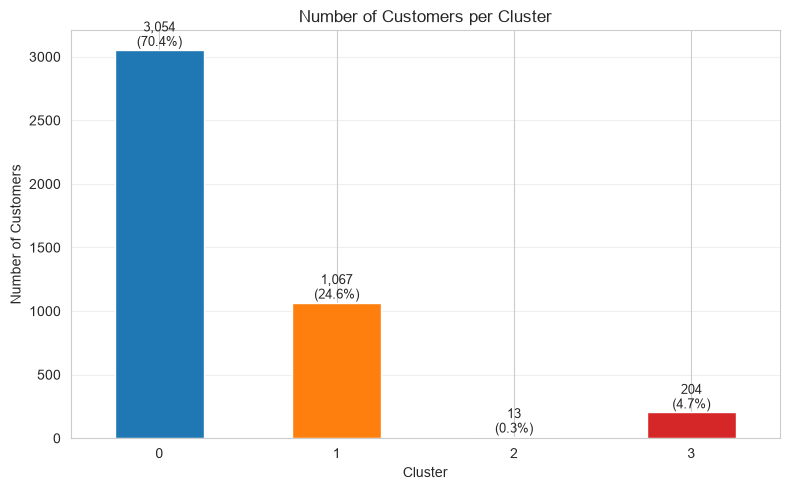

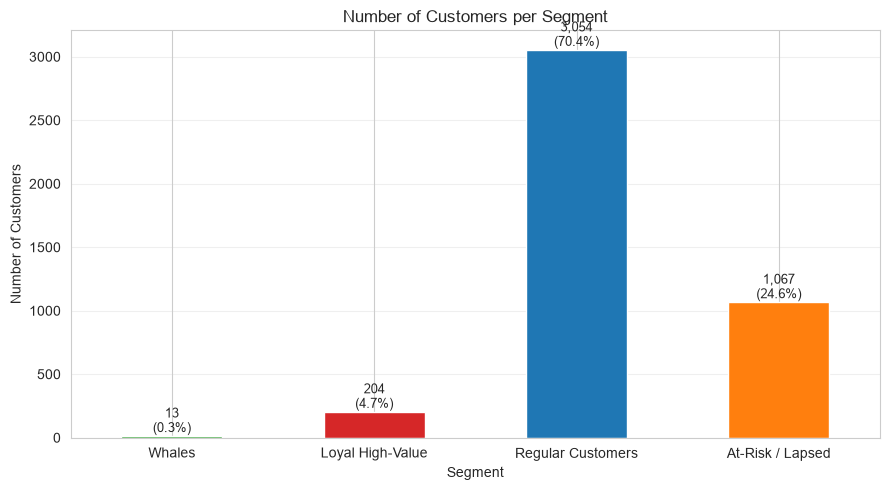

In [11]:

counts = customers["Cluster"].value_counts().sort_index()
print("Customers per cluster:")
print(counts.to_string())
print("\nShare of the customer base:")
print((counts / counts.sum() * 100).round(1).to_string())

fig, ax = plt.subplots(figsize=(8, 5))
bars = counts.plot(kind="bar", color=[palette[c] for c in counts.index])
ax.set_title("Number of Customers per Cluster")
ax.set_xlabel("Cluster")
ax.set_ylabel("Number of Customers")
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", alpha=0.3)
for i, v in enumerate(counts.values):
    ax.text(i, v, f"{v:,}\n({v / counts.sum() * 100:.1f}%)",
            ha="center", va="bottom", fontsize=9)
plt.tight_layout()
fig.savefig(root / "outputs" / "figures" / "customers_per_cluster.png", dpi=150)
plt.show()

# The same counts, labelled with the business segment names.
seg_counts = customers["Segment"].value_counts()
order = ["Whales", "Loyal High-Value", "Regular Customers", "At-Risk / Lapsed"]
seg_counts = seg_counts.reindex([s for s in order if s in seg_counts.index])

fig, ax = plt.subplots(figsize=(9, 5))
seg_palette = {SEGMENT_NAMES[c]: palette[c] for c in palette}
seg_counts.plot(kind="bar", color=[seg_palette[s] for s in seg_counts.index])
ax.set_title("Number of Customers per Segment")
ax.set_xlabel("Segment")
ax.set_ylabel("Number of Customers")
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", alpha=0.3)
for i, v in enumerate(seg_counts.values):
    ax.text(i, v, f"{v:,}\n({v / seg_counts.sum() * 100:.1f}%)",
            ha="center", va="bottom", fontsize=9)
plt.tight_layout()
fig.savefig(root / "outputs" / "figures" / "customers_per_segment.png", dpi=150)
plt.show()


**Observation — segment sizes:** the two bar charts above show the same customer counts, first by cluster ID and then by business segment name.

- **Regular Customers (cluster 0) are the mass: 3,054 customers, 70.4%.**
- **At-Risk / Lapsed (cluster 1) is the second-largest block: 1,067 customers, 24.6%** — more than one customer in four has not bought recently.
- **Whales (cluster 2) and Loyal High-Value (cluster 3) are only 217 customers, 5.0% combined**, even though they carry 47.7% of revenue. The extreme class imbalance in this bar chart is the reason the scatter plots above are plotted on **log axes** — on linear axes the 3,054-customer cluster flattens the other three into a single line along the bottom.

## 10. Name the segments and recommend a marketing action for each


Each cluster was given a plain-language name in step 6 (right after the model was fitted) and the table below restates the
profile in those business terms. The names are assigned by rank on mean spend so they stay correct if the data changes; the
guard in step 6 fails loudly if the clustering no longer produces the four distinct shapes the labels describe.


In [12]:

# Segment summary in business terms.
segment_summary = customers.groupby("Segment").agg(
    Customers=("Total_Revenue", "size"),
    Mean_Recency_days=("Recency", "mean"),
    Mean_Orders=("Purchase_Frequency", "mean"),
    Mean_Order_Value=("Average_Purchase_Value", "mean"),
    Mean_Spend=("Total_Revenue", "mean"),
    Mean_CLV_proxy=("CLV_proxy", "mean"),
).round(2)
segment_summary["% of customers"] = (
    segment_summary["Customers"] / segment_summary["Customers"].sum() * 100).round(1)
segment_summary["% of revenue"] = (
    customers.groupby("Segment")["Total_Revenue"].sum()
    / customers["Total_Revenue"].sum() * 100).round(1)

order = ["Whales", "Loyal High-Value", "Regular Customers", "At-Risk / Lapsed"]
segment_summary = segment_summary.reindex([s for s in order if s in segment_summary.index])
print("Business summary by segment:")
print(segment_summary.to_string())


Business summary by segment:
                   Customers  Mean_Recency_days  Mean_Orders  Mean_Order_Value  Mean_Spend  Mean_CLV_proxy  % of customers  % of revenue
Segment                                                                                                                                 
Whales                    13               7.38        82.54           8570.73   127338.31       248548.05             0.3          18.6
Loyal High-Value         204              15.50        22.33           1080.41    12709.09        24806.51             4.7          29.1
Regular Customers       3054              43.70         3.68            376.76     1359.05         2652.69            70.4          46.6
At-Risk / Lapsed        1067             248.08         1.55            314.81      480.62          938.10            24.6           5.8


**Observation — segment summary in business terms:** the table above restates the same clusters with names attached.

| Segment | Customers | % of base | Mean recency (days) | Mean orders | Mean order value | Mean spend | % of revenue |
|---|---|---|---|---|---|---|---|
| Whales | 13 | 0.3% | 7.4 | 82.5 | 8,570.73 | 127,338.31 | 18.6% |
| Loyal High-Value | 204 | 4.7% | 15.5 | 22.3 | 1,080.41 | 12,709.09 | 29.1% |
| Regular Customers | 3,054 | 70.4% | 43.7 | 3.7 | 376.76 | 1,359.05 | 46.6% |
| At-Risk / Lapsed | 1,067 | 24.6% | 248.1 | 1.6 | 314.81 | 480.62 | 5.8% |

Two things stand out. First, the four segments span a **27× range in mean order value** (8,570.73 down to 314.81) and a **265× range in mean spend** (127,338.31 down to 480.62) — these are genuinely different kinds of customer, not arbitrary subdivisions. Second, the mean CLV proxy scales the same way (248,548.05 → 24,806.51 → 2,652.69 → 938.10), so a marketing budget allocated by CLV would put roughly **265× more per customer** into the Whales than into the At-Risk group.


### Recommended action per segment

Each action below cites the measured value it rests on, so the recommendation can be traced back to a specific number
computed earlier in this notebook.

---

**1. Whales — 13 customers (0.3% of the base, 18.6% of revenue)**
*Evidence: mean recency 7.4 days, mean 82.5 orders, mean spend 127,338, mean order value 8,570.73.*
**Action:** hand-manage these accounts — named account manager, early access to new lines, and a service-level promise on
delivery. Do **not** put them on discount promotions: with a mean order value of 8,570.73 against a portfolio mean of 419.17,
even a 5% discount on their orders gives away about **82,770** of revenue — more than the entire lifetime spend of **172
average lapsed customers**. Their **mean CLV proxy of 248,548.05 per customer** also means a single one of them is worth
roughly **half the entire annual revenue of the whole At-Risk / Lapsed segment** (512,818.85 across 1,067 customers, 5.8% of
revenue).

**2. Loyal High-Value — 204 customers (4.7% of the base, 29.1% of revenue, 24.6% of orders)**
*Evidence: mean recency 15.5 days, mean 22.3 orders, mean spend 12,709, mean order value 1,080.41.*
**Action:** convert them into a subscription or replenishment programme. They already buy roughly every **17 days**
(22.3 orders across the 374-day window) and their median order value of 8,037.73 is **12× the portfolio median order value of
674.48** — the profile is almost perfectly suited to an automatic reorder cycle. Concentrate the loyalty-reward budget here: it
is the largest segment by revenue after the whales and the one whose spend is growing from an already-high base.

**3. Regular Customers — 3,054 customers (70.4% of the base, 46.6% of revenue, 60.7% of orders)**
*Evidence: mean recency 43.7 days, mean 3.68 orders, mean spend 1,359 (median 829), mean order value 376.76.*
**Action:** this is the segment with the most room to grow, because it already generates **46.6% of revenue** but each customer
is worth only about 1,359. Run a **second-purchase activation** campaign here, not a blanket one: with a median of only
3 orders per customer, moving them from 3 to 4 orders is worth more incremental revenue than any reactivation effort.
Targeted cross-sell of adjacent categories is the right mechanism, since their order value (376.76) sits between the lapsed
group and the loyal group, meaning they have room to trade up.

**4. At-Risk / Lapsed — 1,067 customers (24.6% of the base, 5.8% of revenue, 8.9% of orders)**
*Evidence: mean recency 248.1 days (median 243 — more than eight months), mean 1.55 orders (median 1), mean spend 480.62,
mean order value 314.81.*
**Action:** run a low-cost **win-back** email/SMS campaign with a time-boxed incentive, and set a hard budget cap. The economics
are unattractive on a per-customer basis: 1,067 people generating only 5.8% of revenue, whose median spend is just
310.47 and median order value 314.81. A 10% incentive costs about **31 per activated customer**; if every one of the 1,067
bought one more order at their median spend, the incentive would cost **33,127** in total in exchange for at most
**331,271** of recovered revenue — a 10:1 gross ratio *before* margin and before the
reputational cost of discounting to customers who were never going to return. Prioritise within this segment by
**most recent first** (the ones at 180–240 days) and let the 300+ day tail lapse: they are the least likely to return and
should be suppressed to protect the email channel's engagement for everyone else.

---

**Cross-segment insight:** clusters 2 and 3 hold **5.0% of customers but 47.7% of revenue**, while the 1,067 lapsed customers hold
**24.6% of the base for 5.8% of revenue**. The highest-return use of a marketing budget is therefore (a) protecting the
high-value segments, and (b) moving the *Regular* segment up one order per year — not (c) spending heavily to win back the lapsed.


## 11. Save the processed customer-level segmentation

In [13]:

processed = root / "data" / "processed"
processed.mkdir(parents=True, exist_ok=True)

out = customers[[
    "CustomerID", "First_Purchase", "Last_Purchase", "Recency",
    "Purchase_Frequency", "Total_Revenue", "Average_Purchase_Value",
    "Customer_Lifetime_Days", "Annual_Purchase_Frequency", "CLV_proxy",
    "Line_Items", "Total_Quantity", "Country", "Cluster", "Segment",
]].sort_values("Total_Revenue", ascending=False)

out_csv = processed / "customer_segmentation.csv"
out.to_csv(out_csv, index=False)
print("Saved customer-level segmentation:", out_csv)
print("Shape:", out.shape)
print(out.head(5).to_string(index=False))

print("\nAll figures in", root / "outputs" / "figures")
for p in sorted((root / "outputs" / "figures").glob("*.png")):
    print(f"  {p.name}  ({p.stat().st_size / 1024:.0f} KB)")


Saved customer-level segmentation: C:\Users\sohan\OneDrive\Desktop\OIBSIP\DataAnalytics-L1-CustomerSegmentation\data\processed\customer_segmentation.csv
Shape: (4338, 15)
 CustomerID      First_Purchase       Last_Purchase  Recency  Purchase_Frequency  Total_Revenue  Average_Purchase_Value  Customer_Lifetime_Days  Annual_Purchase_Frequency     CLV_proxy  Line_Items  Total_Quantity        Country  Cluster Segment
    14646.0 2010-12-20 10:09:00 2011-12-08 12:12:00        2                  73      280206.02             3838.438630                     354                  71.243316 546926.188770        2076          196915    Netherlands        2  Whales
    18102.0 2010-12-07 16:42:00 2011-12-09 11:50:00        1                  60      259657.30             4327.621667                     367                  58.556150 506817.724599         431           64124 United Kingdom        2  Whales
    17450.0 2010-12-07 09:23:00 2011-12-01 13:29:00        8                  46      194550.7

---

## Summary
- Loaded the UCI Online Retail transaction file (541,909 line items) and applied a logged cleaning pipeline
- Aggregated to one row per customer (never treating an invoice as a customer)
- Derived and defined APV, purchase frequency and a clearly-labelled CLV proxy
- Selected Recency / Frequency / Monetary, standardised them with `StandardScaler`
- Chose K with the elbow method, cross-checked against silhouette scores, and fitted K-Means with `random_state=42`
- Visualised the segments with two different feature-pair scatter plots
- Profiled every cluster with mean and median values and turned each into a marketing action
- Saved the customer-level segmentation to `data/processed/` and the charts to `outputs/figures/`